In [53]:
%pip install pyvi


Note: you may need to restart the kernel to use updated packages.


In [54]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


# Han digit

In [97]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
import pandas as pd
from os import listdir
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay,confusion_matrix, precision_score, f1_score, recall_score , RocCurveDisplay
from sklearn.model_selection import GridSearchCV, train_test_split
from pyvi.ViTokenizer import  tokenize
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer , TfidfVectorizer

In [56]:
matrix = np.array( [
    [0 ,255 ,255 , 0, 0, 0 ,255 , 255],
    [0 ,255, 0, 255, 255 ,255 , 0, 255],
    [255 ,0 ,0, 0, 0, 0 ,0, 255],
    [255 ,0 ,0, 0, 0, 0 , 0, 255],
    [0 ,255 ,0, 0, 0, 0 ,0 ,  255],
    [0 ,0 ,255, 0, 0, 0 ,0 ,  255],
    [0 ,0 ,0, 255, 0, 0 , 255, 0],
    [0, 0, 0, 0 ,255 , 255, 0, 0],
])
matrix

array([[  0, 255, 255,   0,   0,   0, 255, 255],
       [  0, 255,   0, 255, 255, 255,   0, 255],
       [255,   0,   0,   0,   0,   0,   0, 255],
       [255,   0,   0,   0,   0,   0,   0, 255],
       [  0, 255,   0,   0,   0,   0,   0, 255],
       [  0,   0, 255,   0,   0,   0,   0, 255],
       [  0,   0,   0, 255,   0,   0, 255,   0],
       [  0,   0,   0,   0, 255, 255,   0,   0]])

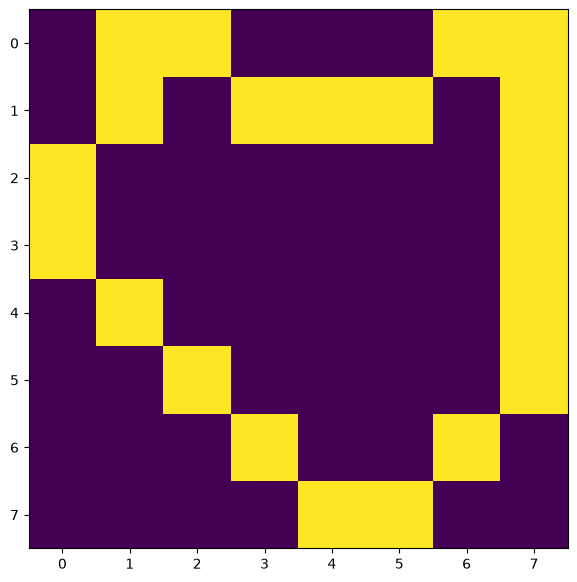

In [57]:
plt.imshow(matrix)
plt.show()

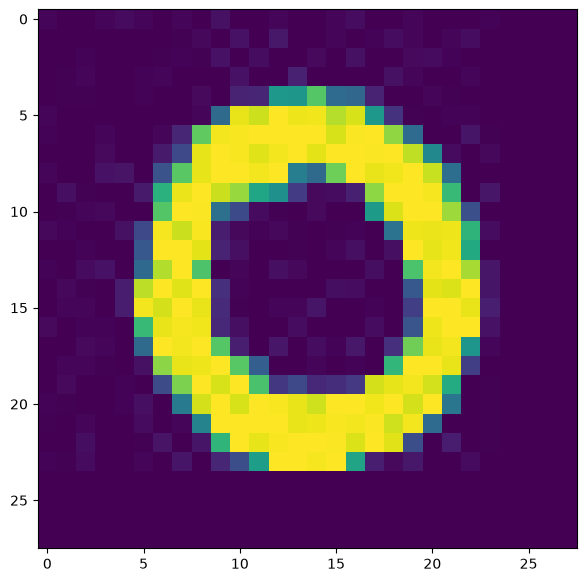

In [58]:
img = cv2.imread('handdigits/0/img_1.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(img)
plt.show()

In [59]:
X = []
y = []
for num in listdir('./handdigits'):
    names = listdir(f'./handdigits/{num}')
    y += [int(num)] * len(names)
    for name in names:
        #matrix
        img = cv2.imread(f'./handdigits/{num}/{name}', cv2.IMREAD_GRAYSCALE)
        # MISS
        #matrix => vector 1d
        X.append(img.flatten())

X = np.array(X)
y = np.array(y)

In [60]:
X.shape, y.shape

((42000, 784), (42000,))

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn.score(X_train, y_train), knn.score(X_test, y_test)

(0.9777460317460317, 0.9647619047619047)

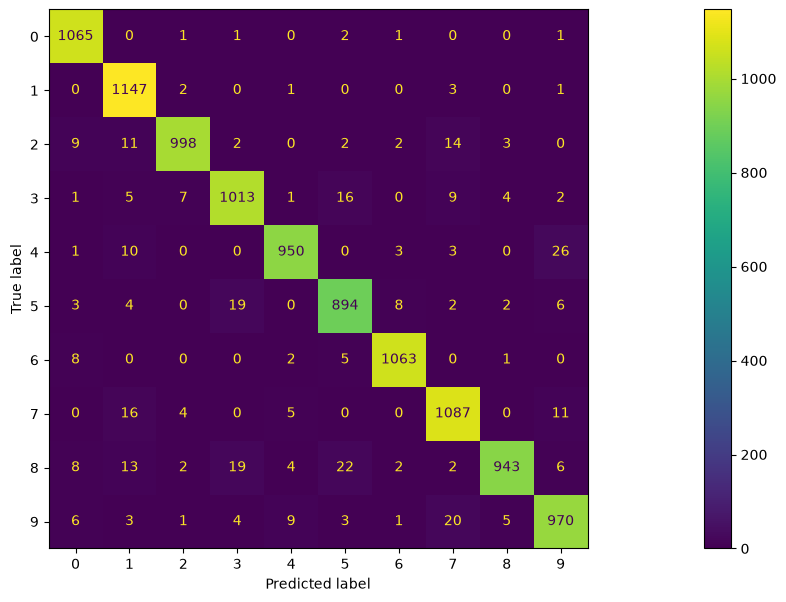

In [62]:
ConfusionMatrixDisplay.from_estimator(knn, X_test, y_test)
plt.show()

In [63]:
y_test_pred = knn.predict(X_test)
y_test_pred.shape

(10500,)

In [64]:
print('Precision score', precision_score(y_test, y_test_pred, average='macro'))
print('Recall score', recall_score(y_test, y_test_pred, average='macro'))
print('F1 score', f1_score(y_test, y_test_pred, average='macro'))

Precision score 0.9651440709225007
Recall score 0.9640119094519026
F1 score 0.9643769754408709


In [65]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
dt.score(X_train, y_train), dt.score(X_test, y_test)

(1.0, 0.8400952380952381)

In [66]:
grid = GridSearchCV(dt, param_grid={
    'max_depth': [11 , 12 ,14 ,20]
})
grid.fit(X_train, y_train)
grid.best_score_, grid.best_params_

(np.float64(0.8327301587301588), {'max_depth': 12})

In [67]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
rf.score(X_train, y_train), rf.score(X_test, y_test)

(1.0, 0.9579047619047619)

In [68]:
grid = GridSearchCV(rf, param_grid={
    'max_depth': [11 , 14 ,23 ,30]
})
grid.fit(X_train, y_train)
grid.best_score_, grid.best_params_

(np.float64(0.9568888888888889), {'max_depth': 30})

In [69]:
validation = []
models = {
    'KNN': knn,
    'Decision Tre': dt,
    'Random Forest': rf
}
for k in models:
    y_test_pred = models[k].predict(X_test)
    validation.append({
        'Model': k,
        'Score': models[k].score(X_test, y_test),
        'Precision': precision_score(y_test, y_test_pred, average='macro'),
        'Recal': recall_score(y_test, y_test_pred, average='macro'),
        'F1-score': f1_score(y_test, y_test_pred, average='macro'),
    })
pd.DataFrame(validation)

,Model,Score,Precision,Recal,F1-score
0,KNN,0.964762,0.965144,0.964012,0.964377
1,Decision Tre,0.840095,0.837656,0.837736,0.837673
2,Random Forest,0.957905,0.957504,0.957425,0.957435


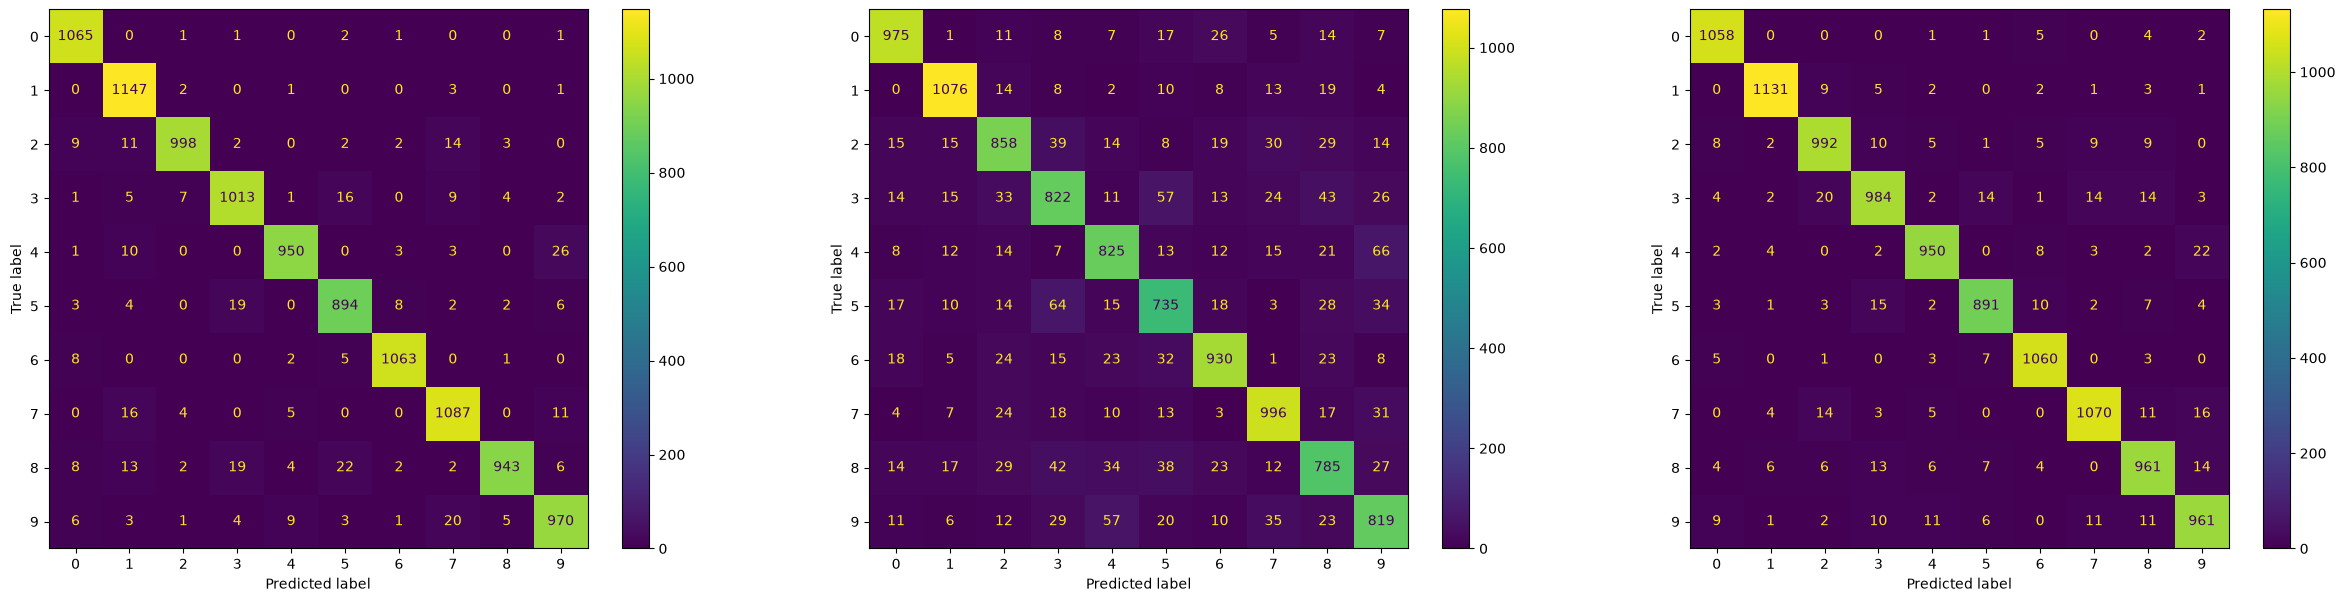

In [70]:
plt.rcParams['figure.figsize'] = (30,7)
fig , axes = plt.subplots (ncols=3)
for i , k in enumerate(models):
    ConfusionMatrixDisplay.from_estimator(models[k],X_test,y_test, ax=axes[i])
plt.show() 

# Sentiment Analysys

In [71]:
df_train = pd.read_csv('./data/Train.csv')
df_train.head()

,index,comment,n_star,date_time,label
0,0,Mới mua máy này Tại thegioididong thốt nốt cảm...,5,2 tuần trước,{CAMERA#Positive};{FEATURES#Positive};{BATTERY...
1,1,Pin kém còn lại miễn chê mua 8/3/2019 tình trạ...,5,14/09/2019,{BATTERY#Negative};{GENERAL#Positive};{OTHERS};
2,2,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nh...,3,17/08/2020,{FEATURES#Negative};
3,3,"Mọi người cập nhật phần mềm lại , nó sẽ bớt tố...",3,29/02/2020,{FEATURES#Negative};{BATTERY#Neutral};{GENERAL...
4,4,"Mới mua Sài được 1 tháng thấy pin rất trâu, Sà...",5,4/6/2020,{BATTERY#Positive};{PERFORMANCE#Positive};{SER...


In [72]:
df_train['n_star'].unique()

array([5, 3, 1, 2, 4])

In [73]:
df_train['y'] = df_train['n_star'].apply(lambda v: 'Positive' if v >= 4 else 'Negative')

In [74]:
df_train.head()

,index,comment,n_star,date_time,label,y
0,0,Mới mua máy này Tại thegioididong thốt nốt cảm...,5,2 tuần trước,{CAMERA#Positive};{FEATURES#Positive};{BATTERY...,Positive
1,1,Pin kém còn lại miễn chê mua 8/3/2019 tình trạ...,5,14/09/2019,{BATTERY#Negative};{GENERAL#Positive};{OTHERS};,Positive
2,2,Sao lúc gọi điện thoại màn hình bị chấm nhỏ nh...,3,17/08/2020,{FEATURES#Negative};,Negative
3,3,"Mọi người cập nhật phần mềm lại , nó sẽ bớt tố...",3,29/02/2020,{FEATURES#Negative};{BATTERY#Neutral};{GENERAL...,Negative
4,4,"Mới mua Sài được 1 tháng thấy pin rất trâu, Sà...",5,4/6/2020,{BATTERY#Positive};{PERFORMANCE#Positive};{SER...,Positive


In [75]:
tokenize(df_train['comment'][2])

'Sao lúc gọi điện_thoại màn_hình bị chấm nhỏ nháy gần camera trước_vậy ( lúc có lúc không )'

In [76]:
df_train['comment_tokenize'] = df_train['comment'].apply(tokenize)

In [77]:
count = CountVectorizer()
X_train = count.fit_transform(df_train['comment_tokenize'])
y_train = df_train['y']
X_train.shape, y_train.shape

((7786, 8681), (7786,))

In [78]:
df_test = pd.read_csv('./data/Test.csv')
df_test.head()

,index,comment,n_star,date_time,label
0,0,"Điện thoải ổn. Facelock cực nhanh, vân tay ôk ...",5,5/2/2020,{SCREEN#Positive};{FEATURES#Positive};{PERFORM...
1,1,"Mình mới mua vivo91c. Tải ứng dụng ,games nh...",5,14/05/2019,{FEATURES#Negative};{PERFORMANCE#Positive};{SE...
2,2,Xấu đẹp gì ko biết nhưng rất ưng TGdđ phục vụ ...,5,26/03/2020,{DESIGN#Neutral};{SER&ACC#Positive};
3,3,Màn hình hơi lác khi chơi game. Game nặng thì ...,4,4/6/2019,{PERFORMANCE#Negative};{DESIGN#Negative};{OTHE...
4,4,"Nói chung máy đẹp với màn amoled, ổn trong tầm...",4,12/5/2020,{SCREEN#Positive};{BATTERY#Negative};{DESIGN#P...


In [79]:
df_test['y'] = df_test['n_star'].apply(lambda v: 'Positive' if v >= 4 else 'Negative')

In [80]:
df_test['comment_tokenize'] = df_test['comment'].apply(tokenize)

In [81]:
X_test = count.transform(df_test['comment_tokenize'])
y_test = df_test['y']
X_test.shape, y_test.shape

((2224, 8681), (2224,))

In [82]:
nb = MultinomialNB()
nb.fit(X_train, y_train)
nb.score(X_train, y_train), nb.score(X_test, y_test)

(0.8811970202928333, 0.835431654676259)

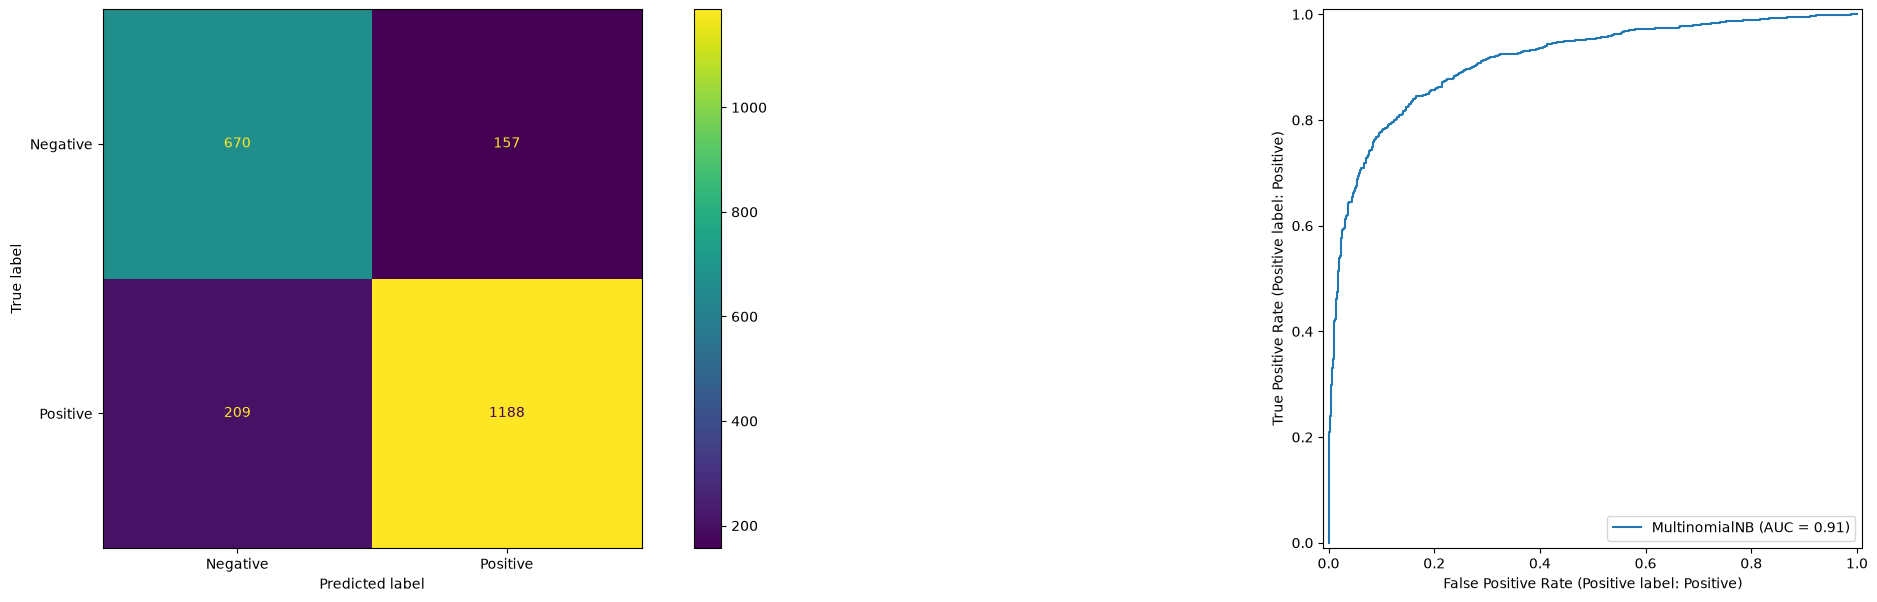

In [85]:
fig, axes = plt.subplots(ncols=2)
ConfusionMatrixDisplay.from_estimator(nb, X_test, y_test, ax=axes[0])
RocCurveDisplay.from_estimator(nb, X_test, y_test, ax=axes[1])
plt.show()

In [86]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
rf.score(X_train, y_train), rf.score(X_test, y_test)

(0.9998715643462626, 0.8372302158273381)

In [87]:
grid = GridSearchCV(rf, param_grid={
    'max_depth': [200 , 300 , 40, 500 ,1000]
})
grid.fit(X_train, y_train)
grid.best_score_, grid.best_params_

(np.float64(0.837398209090092), {'max_depth': 300})

In [88]:
rf = RandomForestClassifier(max_depth=200)
rf.fit(X_train, y_train)
rf.score(X_train, y_train), rf.score(X_test, y_test)

(0.9998715643462626, 0.8385791366906474)

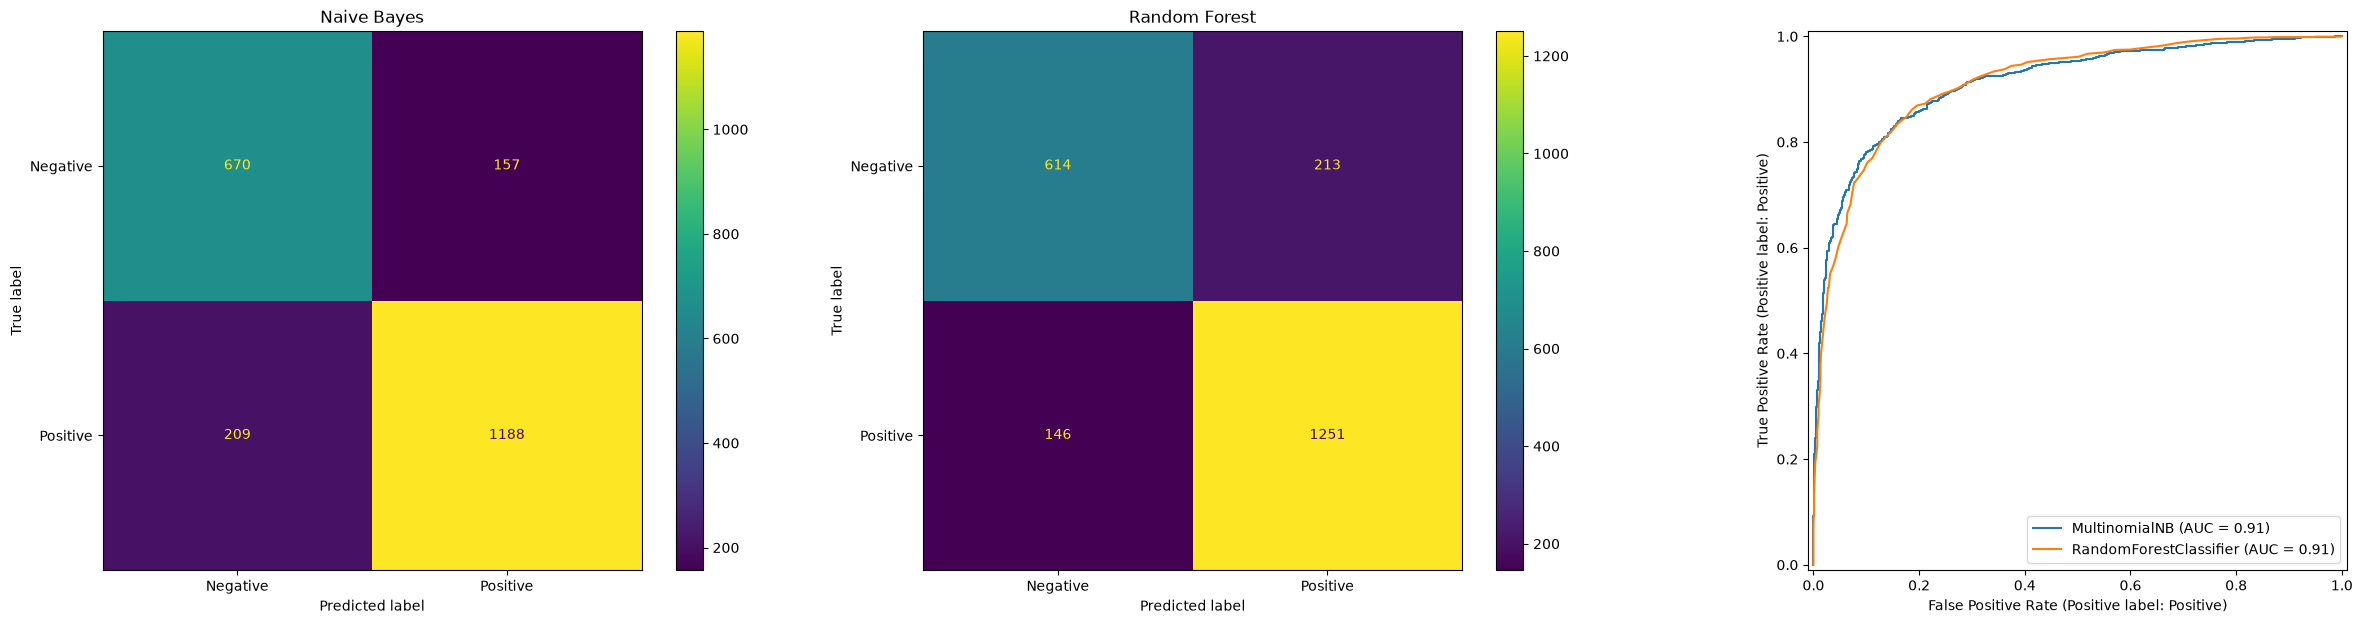

In [89]:
fig, axes = plt.subplots(ncols=3)
axes[0].set_title('Naive Bayes')
ConfusionMatrixDisplay.from_estimator(nb, X_test, y_test, ax=axes[0])
axes[1].set_title('Random Forest')
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, ax=axes[1])
RocCurveDisplay.from_estimator(nb, X_test, y_test, ax=axes[2])
RocCurveDisplay.from_estimator(rf, X_test, y_test, ax=axes[2])
plt.show()


In [90]:
tfidf = TfidfVectorizer()
X_train_tf = tfidf.fit_transform(df_train['comment_tokenize'])
X_test_tf = tfidf.transform(df_test['comment_tokenize'])


In [91]:
nb = MultinomialNB()
nb.fit(X_train_tf, y_train)
nb.score(X_train_tf, y_train), nb.score(X_test, y_test)


(0.8452350372463396, 0.8160971223021583)

In [92]:
y_test_pred_tfidf_nb = nb.predict(X_test_tf)


In [93]:
rf = RandomForestClassifier(max_depth=300)
rf.fit(X_train_tf, y_train)
rf.score(X_train_tf, y_train), rf.score(X_test, y_test)


(0.9998715643462626, 0.8381294964028777)

In [94]:
y_test_pred_tfidf_rf = rf.predict(X_test_tf)


In [95]:
y_test_pred_tfidf_nb.shape, y_test.shape


((2224,), (2224,))

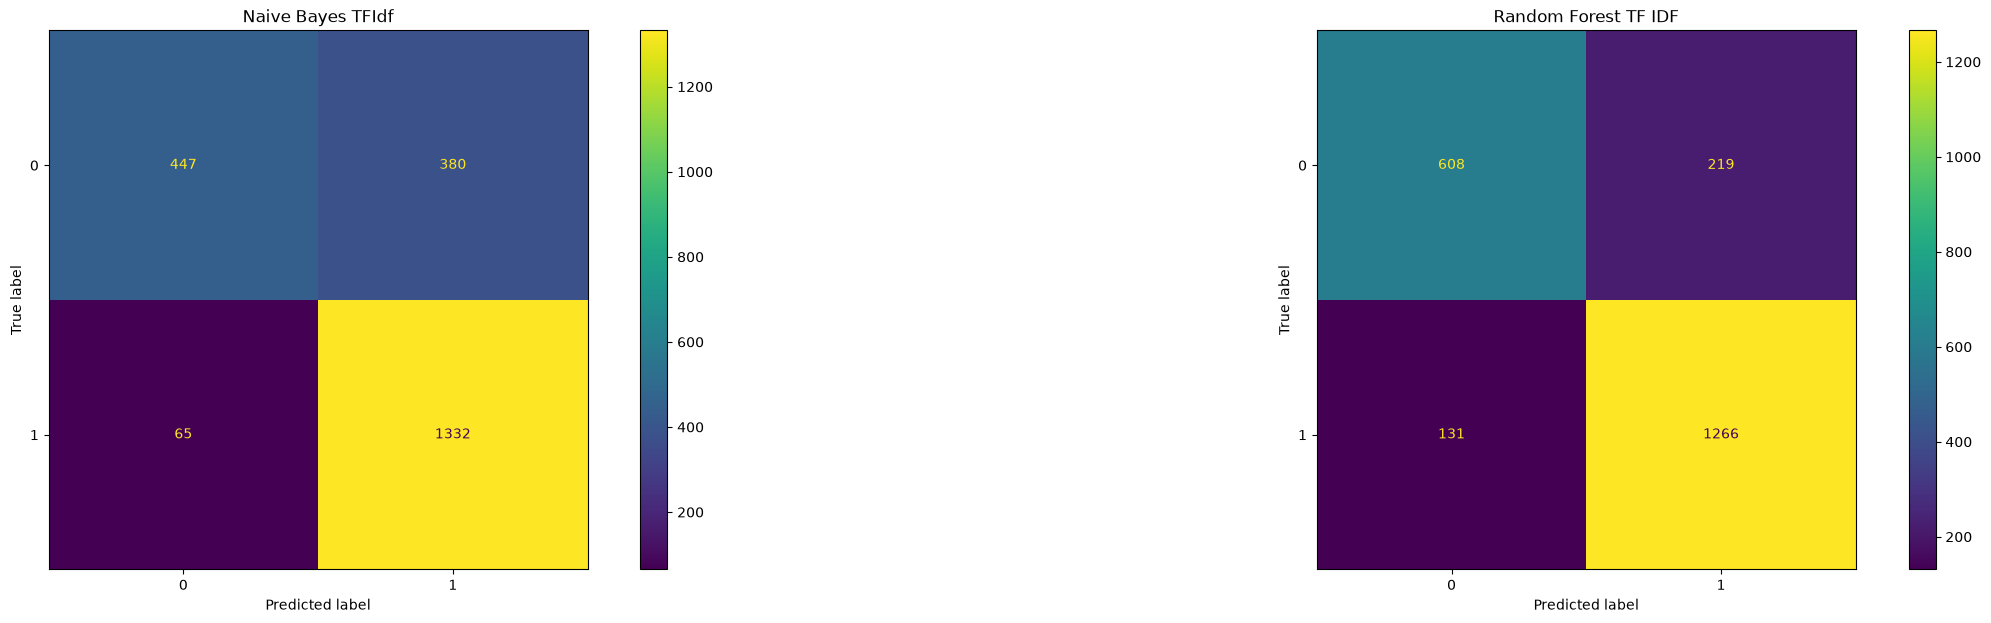

In [98]:
fig, axes = plt.subplots(ncols=2)
axes[0].set_title('Naive Bayes TFIdf')
cmd = ConfusionMatrixDisplay(confusion_matrix(y_test, y_test_pred_tfidf_nb))
cmd.plot(ax = axes[0])
axes[1].set_title('Random Forest TF IDF')
cmd = ConfusionMatrixDisplay(confusion_matrix(y_test, y_test_pred_tfidf_rf))
cmd.plot(ax = axes[1])
plt.show()
